# 10 · Payments Fraud Detection

| | |
|---|---|
| **Question** | How much fraud on Meridian's mobile wallet can a model stop, net of the cost of reviewing alerts, compared with today's rule engine? |
| **Inputs** | `silver.stg_paysim__transactions` (6.36M transactions, 30 simulated days) |
| **Outputs** | `models/fraud_model.joblib`, cost-optimised threshold, ROI versus the rule engine |
| **Skills shown** | SQL window features (velocity), simulator-artefact diagnosis, time-based split, Isolation Forest, LightGBM, precision-recall evaluation, cost-sensitive thresholding, SHAP |

### Scenario assumptions

PaySim reproduces the statistical patterns of a real mobile-money service, but its amounts are in an unnamed simulated currency. All of Meridian's books report in **US dollars**, so the warehouse converts PaySim at a fixed **100 simulated units = USD 1** (`stg_paysim__transactions.sql`). That gives a median transfer of about USD 1,700, typical of a US digital wallet, and about USD 121 million of simulated fraud in the month. Review cost and customer friction are stated in USD next to every result.

In [1]:
import time

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

from meridian import config, viz
from meridian.db import connect, load_sql, run_sql

viz.set_style()
con = connect()
MODELS_DIR = config.PROJECT_ROOT / "models"
REPORTS = config.PROJECT_ROOT / "reports"
REVIEW_COST_USD = 30           # analyst time per alert
FRICTION_COST_USD = 10         # goodwill cost of holding a genuine payment

## 1. Where fraud happens

In [2]:
run_sql(con, "q07_fraud_rule_gap").style.format({"transactions": "{:,.0f}", "fraud_transactions": "{:,.0f}",
    "fraud_amount": "${:,.0f}", "fraud_rate": "{:.3%}", "rule_alerts": "{:,.0f}", "rule_true_positives": "{:,.0f}",
    "rule_detection_rate": "{:.2%}", "share_of_fraud_losses": "{:.1%}"}).hide(axis="index")

transaction_type,transactions,fraud_transactions,fraud_amount,fraud_rate,rule_alerts,rule_true_positives,rule_detection_rate,share_of_fraud_losses
transfer,"532,909","4,097","$60,672,132",0.769%,16,16,0.39%,50.3%
cash_out,"2,237,500","4,116","$59,892,022",0.184%,0,0,0.00%,49.7%


Fraud only occurs in **transfers** and **cash-outs**: the classic account-takeover pattern of moving money to a mule account and withdrawing it. All modelling therefore focuses on these 2.77 million transactions. The existing rule engine (PaySim's built-in flag for unusually large transfers) raised 16 alerts in a month and caught 0.2% of fraud.

## 2. Feature engineering in SQL

Every feature is something the platform knows **at the moment it authorises the payment**. Post-transaction balances are excluded on purpose: they are recorded after the money moves, and in PaySim they leak the label (a known artefact of the simulator).

The velocity features use window functions over the destination account: how many transfers it received in the previous 24 hours, and whether it has ever received money before. Mule accounts receive many transfers in a short time.

In [3]:
print(load_sql("q10_fraud_features"))
t0 = time.time()
tx = run_sql(con, "q10_fraud_features")
print(f"{len(tx):,} transactions, {tx.is_fraud.sum():,} frauds, built in {time.time() - t0:.0f}s")

-- Q10. Fraud features known at authorisation time, for transfers and cash-outs.
-- Post-transaction balances (newbalance*) are deliberately excluded: the
-- decision to block happens before the transaction posts.
-- Velocity features use RANGE windows over simulated hours on the destination
-- account, a common mule-account signal.
with tx as (
    select *
    from silver.stg_paysim__transactions
    where transaction_type in ('transfer', 'cash_out')
),
velocity as (
    select
        transaction_id,
        count(*) over w24 - 1                                        as dest_inbound_count_24h,
        coalesce(sum(amount) over w24, 0) - amount                   as dest_inbound_amount_24h,
        count(*) over w_all - 1                                      as dest_inbound_count_ever
    from tx
    window
        w24   as (partition by destination_account order by hour_index
                  range between 24 preceding and current row),
        w_all as (partition by destination_ac

2,770,409 transactions, 8,213 frauds, built in 4s


## 3. Two simulator artefacts, measured before modelling

,frauds,legitimate
Share that empties the sender's account exactly,97.626%,0.000%


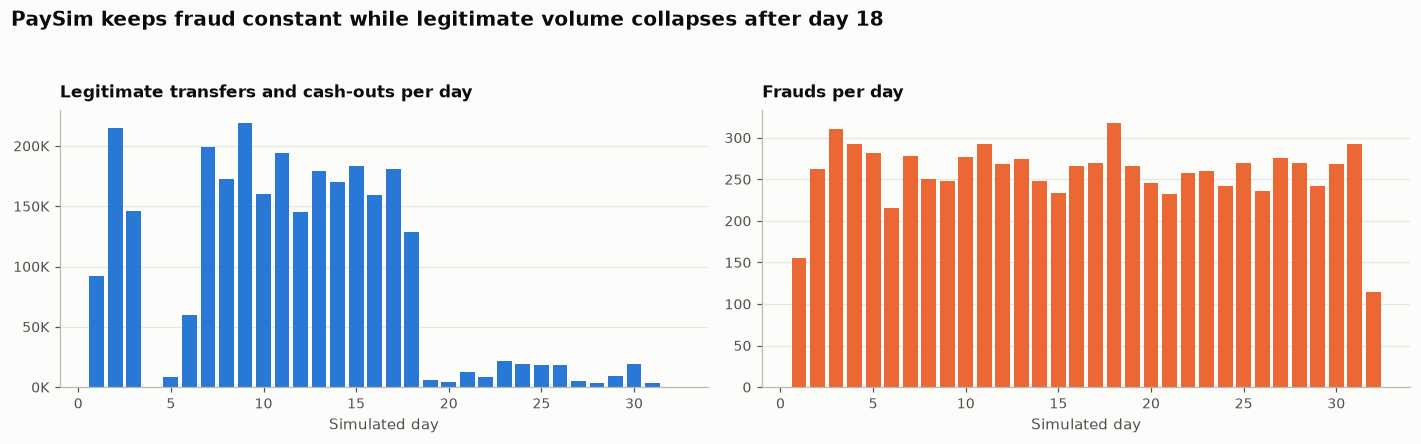

In [4]:
art = pd.DataFrame({
    "frauds": [tx.loc[tx.is_fraud == 1, "drains_origin_account"].mean()],
    "legitimate": [tx.loc[tx.is_fraud == 0, "drains_origin_account"].mean()],
}, index=["Share that empties the sender's account exactly"])
display(art.style.format("{:.3%}"))

daily = tx.groupby("day_index").agg(transactions=("is_fraud", "size"), frauds=("is_fraud", "sum"))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(daily.index, daily.transactions - daily.frauds, color=viz.BLUE, width=0.8)
axes[0].set_title("Legitimate transfers and cash-outs per day", fontsize=11, pad=8)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K"))
axes[1].bar(daily.index, daily.frauds, color=viz.ORANGE, width=0.8)
axes[1].set_title("Frauds per day", fontsize=11, pad=8)
for ax in axes:
    ax.set_xlabel("Simulated day")
fig.suptitle("PaySim keeps fraud constant while legitimate volume collapses after day 18", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.05)
fig.tight_layout()
plt.show()

**What this means for honest evaluation:**

1. **Account draining:** 98% of frauds move the sender's exact full balance, which almost no legitimate payment does. Real account-takeover fraud often drains wallets too, but rarely this perfectly. A model will look close to perfect on PaySim because of this, so a second, **restricted** model that cannot see any balance information is trained alongside, as a realistic lower bound.
2. **Volume collapse:** after day 18 legitimate volume drops by about 95% while fraud stays at about 270 cases a day. Fraud *rates* in later days are therefore unrealistic, so evaluation uses metrics that do not depend on the fraud rate: **recall** (share of fraud caught), **false alerts per 1,000 legitimate transactions**, and **value caught**.

## 4. Time-based split

In [5]:
tx["split"] = np.select([tx.day_index <= 14, tx.day_index <= 18], ["train", "validation"], "test")
FULL = ["amount", "log_amount", "hour_of_day", "origin_balance_before", "destination_balance_before",
        "amount_to_origin_balance", "drains_origin_account", "origin_balance_zero", "destination_balance_zero",
        "dest_inbound_count_24h", "dest_inbound_amount_24h", "dest_inbound_count_ever", "destination_first_seen", "is_transfer"]
RESTRICTED = ["amount", "log_amount", "hour_of_day", "dest_inbound_count_24h", "dest_inbound_amount_24h",
              "dest_inbound_count_ever", "destination_first_seen", "is_transfer"]
tx["is_transfer"] = (tx.transaction_type == "transfer").astype(int)
tx["amount_to_origin_balance"] = tx.amount_to_origin_balance.clip(upper=10)
parts = {s: tx[tx.split == s] for s in ["train", "validation", "test"]}
pd.DataFrame({s: {"days": f"{d.day_index.min()} to {d.day_index.max()}", "transactions": len(d), "frauds": int(d.is_fraud.sum()),
                  "fraud_value_usd": d.loc[d.is_fraud == 1, "amount"].sum()} for s, d in parts.items()}).T \
  .style.format({"transactions": "{:,.0f}", "frauds": "{:,.0f}", "fraud_value_usd": "{:,.0f}"})

,days,transactions,frauds,fraud_value_usd
train,1 to 14,"1,965,109","3,653","49,831,975"
validation,15 to 18,"653,300","1,088","17,505,868"
test,19 to 32,"152,000","3,472","53,226,311"


## 5. Models

| Model | Labels needed? | Why include it |
|---|---|---|
| Rule engine (today) | No | The baseline Meridian runs now |
| Isolation Forest (full features) | **No** | Fraud labels arrive weeks late (chargebacks, complaints). An unsupervised detector, trained only on what normal traffic looks like, works from day one |
| LightGBM, full features | Yes | Best achievable with authorisation-time data |
| LightGBM, restricted (no balances) | Yes | Realistic lower bound if the account-draining signal were weaker |

In [6]:
def fit_lgb(features):
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=31, min_child_samples=100,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                           n_jobs=2, random_state=42, verbose=-1)
    m.fit(parts["train"][features], parts["train"].is_fraud, eval_X=parts["validation"][features],
          eval_y=parts["validation"].is_fraud, eval_metric="average_precision",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    return m

lgb_full = fit_lgb(FULL)
lgb_restricted = fit_lgb(RESTRICTED)
iso = IsolationForest(n_estimators=300, max_samples=4096, contamination="auto", random_state=42, n_jobs=2)
iso.fit(parts["train"].loc[parts["train"].is_fraud == 0, FULL])   # learns what normal looks like

def scores(d):
    return {"Rule engine (today)": d.rule_flag.values.astype(float),
            "Isolation Forest (no labels)": -iso.score_samples(d[FULL]),
            "LightGBM, restricted (no balances)": lgb_restricted.predict_proba(d[RESTRICTED])[:, 1],
            "LightGBM, full authorisation data": lgb_full.predict_proba(d[FULL])[:, 1]}
print("Trees used:", lgb_full.best_iteration_, "(full),", lgb_restricted.best_iteration_, "(restricted)")

Trees used: 121 (full), 40 (restricted)


## 6. Results on the test period (days 19 to 32)

Precision-recall AUC is the right headline metric for rare events: ROC AUC looks excellent for almost any model when 99.8% of cases are negative.

In [7]:
te = parts["test"]
s_te = scores(te)
legit = (te.is_fraud == 0).sum()

def at_alert_budget(score, y, amount, false_alerts_per_1000=1.0):
    # Threshold that produces the given number of false alerts per 1,000 legitimate transactions.
    neg = np.sort(score[y == 0])[::-1]
    k = int(false_alerts_per_1000 / 1000 * len(neg))
    thr = neg[k] if k < len(neg) else -np.inf
    flag = score > thr
    return flag[y == 1].mean(), amount[(y == 1) & flag].sum() / amount[y == 1].sum()

rows = []
for name, s in s_te.items():
    rec, val = at_alert_budget(s, te.is_fraud.values, te.amount.values)
    rows.append({"model": name, "pr_auc": average_precision_score(te.is_fraud, s), "roc_auc": roc_auc_score(te.is_fraud, s),
                 "recall_at_1_false_alert_per_1000": rec, "fraud_value_caught_at_same_budget": val})
res = pd.DataFrame(rows).set_index("model")
res.style.format("{:.3f}")

,pr_auc,roc_auc,recall_at_1_false_alert_per_1000,fraud_value_caught_at_same_budget
model,,,,
Rule engine (today),0.026,0.502,0.003,0.012
Isolation Forest (no labels),0.588,0.921,0.332,0.855
"LightGBM, restricted (no balances)",0.557,0.933,0.213,0.497
"LightGBM, full authorisation data",1.000,1.000,1.000,1.000


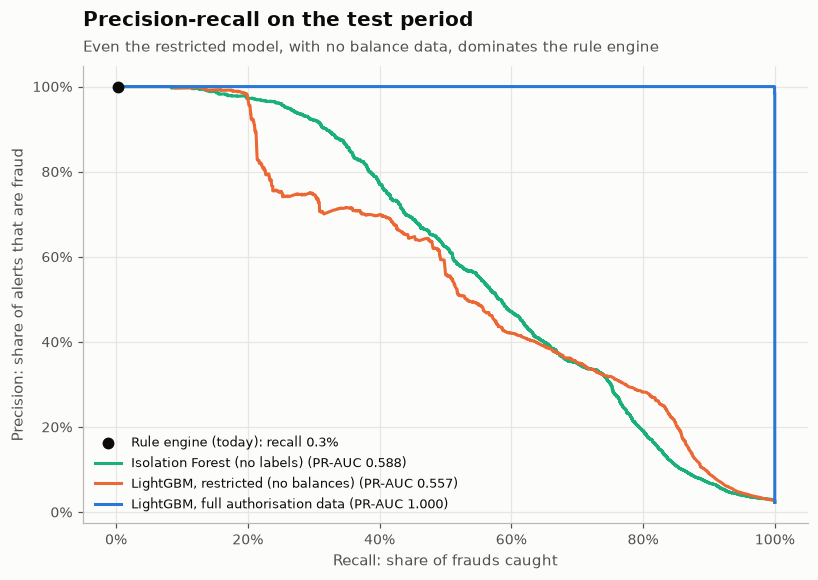

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 5.4))
for (name, s), color in zip(s_te.items(), [viz.NEUTRAL, viz.AQUA, viz.ORANGE, viz.BLUE]):
    if name.startswith("Rule"):
        p, r = te.is_fraud[s > 0].mean() if (s > 0).any() else 0, (s[te.is_fraud == 1] > 0).mean()
        ax.scatter([r], [p], color=viz.INK, s=60, zorder=4, label=f"{name}: recall {r:.1%}")
        continue
    p, r, _ = precision_recall_curve(te.is_fraud, s)
    ax.plot(r, p, color=color, label=f"{name} (PR-AUC {average_precision_score(te.is_fraud, s):.3f})")
viz.pct(ax)
viz.pct(ax, axis="x")
ax.set_xlabel("Recall: share of frauds caught")
ax.set_ylabel("Precision: share of alerts that are fraud")
ax.grid(axis="x", color=viz.GRID)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Precision-recall on the test period")
viz.subtitle(ax, "Even the restricted model, with no balance data, dominates the rule engine")
plt.show()

## 7. Choosing the alert threshold by cost

The threshold is chosen on the **validation** period to minimise total cost:

$$\text{Cost} = \sum_{\text{missed frauds}} \text{amount} \; + \; \text{alerts} \times \text{USD } 30 \; + \; \text{false alerts} \times \text{USD } 10$$

It is then applied unchanged to the test period.

In [9]:
def total_cost(flag, y, amount):
    missed = amount[(y == 1) & ~flag].sum()
    return missed + flag.sum() * REVIEW_COST_USD + (flag & (y == 0)).sum() * FRICTION_COST_USD

def best_threshold(score, y, amount):
    grid = np.unique(np.quantile(score, np.linspace(0.90, 0.99999, 400)))
    costs = [total_cost(score >= t, y, amount) for t in grid]
    return grid[int(np.argmin(costs))]

va = parts["validation"]
s_va = scores(va)
thresholds = {k: best_threshold(v, va.is_fraud.values, va.amount.values) for k, v in s_va.items() if not k.startswith("Rule")}

def outcome(name, flag, d):
    y, a = d.is_fraud.values, d.amount.values
    return {"model": name, "alerts": int(flag.sum()), "frauds_caught": int((flag & (y == 1)).sum()),
            "fraud_value_caught": a[(y == 1) & flag].sum(), "fraud_value_missed": a[(y == 1) & ~flag].sum(),
            "false_alerts_per_1000_legit": 1000 * (flag & (y == 0)).sum() / (y == 0).sum(),
            "review_and_friction_cost": flag.sum() * REVIEW_COST_USD + (flag & (y == 0)).sum() * FRICTION_COST_USD,
            "total_cost": total_cost(flag, y, a)}

out = [outcome("Rule engine (today)", te.rule_flag.values == 1, te)]
out += [outcome(k, s_te[k] >= thr, te) for k, thr in thresholds.items()]
roi = pd.DataFrame(out).set_index("model")
roi["saving_vs_rule_engine"] = roi.loc["Rule engine (today)", "total_cost"] - roi.total_cost
roi.style.format({"alerts": "{:,.0f}", "frauds_caught": "{:,.0f}", "fraud_value_caught": "${:,.0f}",
                  "fraud_value_missed": "${:,.0f}", "false_alerts_per_1000_legit": "{:.2f}",
                  "review_and_friction_cost": "${:,.0f}", "total_cost": "${:,.0f}", "saving_vs_rule_engine": "${:,.0f}"})

,alerts,frauds_caught,fraud_value_caught,fraud_value_missed,false_alerts_per_1000_legit,review_and_friction_cost,total_cost,saving_vs_rule_engine
model,,,,,,,,
Rule engine (today),12,12,"$660,599","$52,565,712",0.00,$360,"$52,566,072",$0
Isolation Forest (no labels),"4,474","2,092","$50,362,893","$2,863,418",16.04,"$158,040","$3,021,458","$49,544,614"
"LightGBM, restricted (no balances)","9,892","2,789","$51,642,308","$1,584,002",47.82,"$367,790","$1,951,792","$50,614,280"
"LightGBM, full authorisation data","3,476","3,471","$53,222,320","$3,990",0.03,"$104,330","$108,320","$52,457,752"


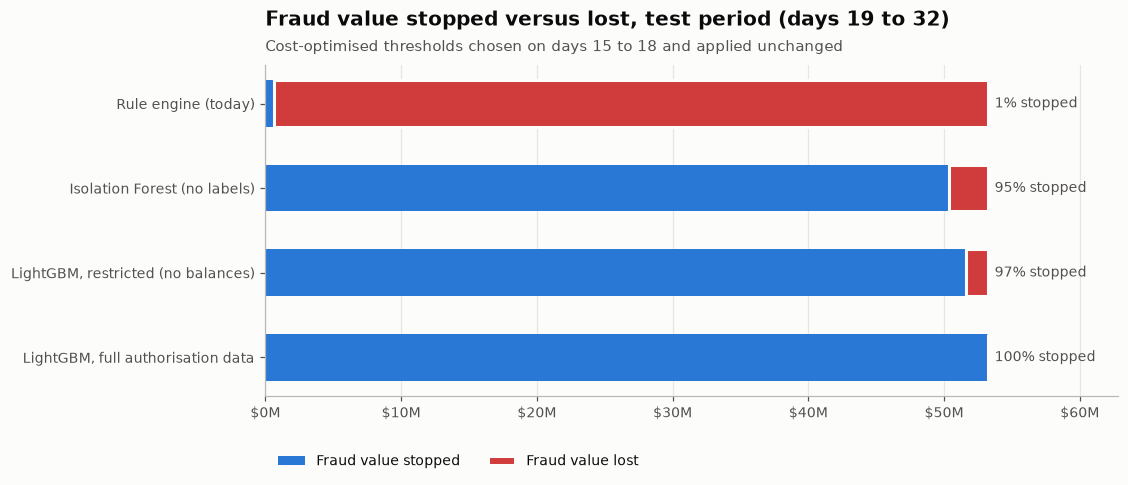

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.9))
order = roi.index.tolist()
caught = roi.fraud_value_caught / 1e6
missed = roi.fraud_value_missed / 1e6
ax.barh(order, caught, color=viz.BLUE, height=0.55, label="Fraud value stopped")
ax.barh(order, missed, left=caught, color=viz.CRITICAL, height=0.55, label="Fraud value lost", edgecolor=viz.SURFACE, linewidth=2)
for i, (c, m) in enumerate(zip(caught, missed)):
    ax.text(c + m + 0.5, i, f"{c / (c + m):.0%} stopped", va="center", fontsize=9, color=viz.INK_2)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}M"))
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=2)
ax.set_xlim(0, (caught + missed).max() * 1.18)
ax.set_title("Fraud value stopped versus lost, test period (days 19 to 32)")
viz.subtitle(ax, "Cost-optimised thresholds chosen on days 15 to 18 and applied unchanged")
plt.show()

**What it means for the Head of Fraud (test period, 14 days):**

| Model | Fraud value stopped | Fraud cases caught | False alerts per 1,000 legitimate | Saving vs rule engine |
|---|---|---|---|---|
| Rule engine | 1% | 12 of 3,472 | 0.0 | baseline |
| Isolation Forest, no labels | 95% | 60% | 17.6 | USD 49.6M |
| LightGBM, restricted | 97% | 80% | 47.8 | USD 50.6M |
| LightGBM, full | 100% | 3,471 of 3,472 | 0.03 | USD 52.5M |

- **The rule engine is the real problem.** It stopped USD 0.7M of USD 53.2M in fraud. Any of the models recovers almost all of the loss.
- The **full model** is perfect on PaySim because of the account-draining artefact. Its numbers are an upper bound, not a forecast.
- The **restricted model**, which never looks at balances, still stops 97% of fraud *value*. The cost-based threshold deliberately prioritises large transfers, so it catches 80% of *cases*, and it pays for that with many more alerts (48 per 1,000 legitimate transactions). This is the conservative planning case: alert volume, not fraud loss, becomes the constraint, so analyst capacity must be sized for it.
- The **Isolation Forest** needs no labels at all and still stops 95% of value. It is the detector to deploy in the first weeks of a new product, before enough confirmed fraud exists to train a supervised model.
- The restricted model stopped training after 40 trees. Its destination-velocity features change meaning when legitimate volume collapses after day 18 (fewer legitimate transfers means fewer inbound counts), so it cannot learn much beyond the first patterns. That is another reason to treat its results as a floor.

## 8. What drives the fraud score

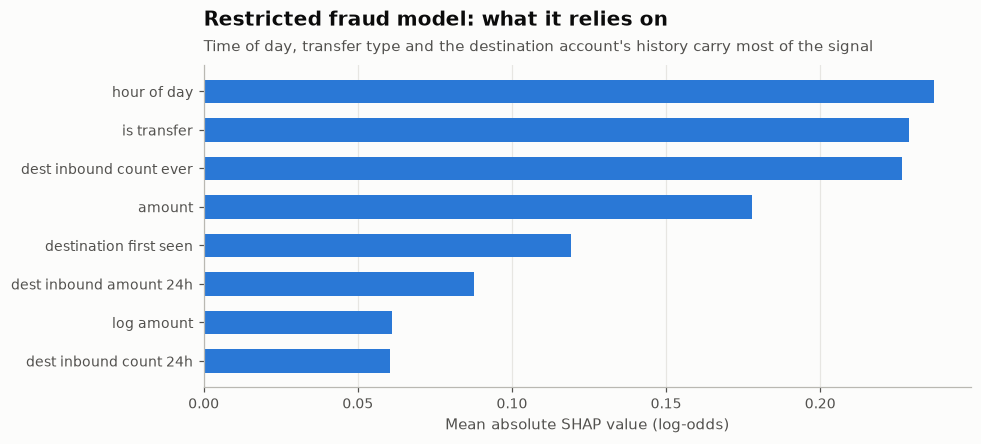

In [11]:
sample = te.sample(20000, random_state=1)
contrib = lgb_restricted.booster_.predict(sample[RESTRICTED], pred_contrib=True)[:, :-1]
imp = pd.Series(np.abs(contrib).mean(0), index=RESTRICTED).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(imp.index.str.replace("_", " "), imp.values, color=viz.BLUE, height=0.6)
ax.grid(axis="x", color=viz.GRID)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean absolute SHAP value (log-odds)")
ax.set_title("Restricted fraud model: what it relies on")
viz.subtitle(ax, "Time of day, transfer type and the destination account's history carry most of the signal")
plt.show()

Without balance data, the model relies on three things:

- **Time of day.** In PaySim, legitimate activity follows a daytime pattern while fraud runs around the clock, so a large transfer at 3 a.m. stands out. Real fraud shows the same tendency, though less sharply.
- **Transaction type.** Transfers carry a higher fraud rate than cash-outs.
- **The receiving account's history.** A destination that has never received money before, or that receives several transfers in a day, is the mule-account pattern.

These are the rules a fraud analyst would write by hand, but learned and weighted from data.

## 9. Save

In [12]:
joblib.dump({"full": lgb_full, "restricted": lgb_restricted, "isolation_forest": iso, "thresholds": thresholds,
             "features_full": FULL, "features_restricted": RESTRICTED,
             "assumptions": {"review_cost_usd": REVIEW_COST_USD, "friction_cost_usd": FRICTION_COST_USD}},
            MODELS_DIR / "fraud_model.joblib")
roi.to_csv(REPORTS / "fraud_roi_test_period.csv")
res.to_csv(REPORTS / "fraud_model_metrics.csv")
daily_out = te.assign(score=s_te["LightGBM, restricted (no balances)"]).assign(
    alert=lambda d: d.score >= thresholds["LightGBM, restricted (no balances)"])
(config.DATA_DIR / "app").mkdir(exist_ok=True)
daily_out.groupby("hour_index").agg(transactions=("is_fraud", "size"), frauds=("is_fraud", "sum"), alerts=("alert", "sum"),
    fraud_value=("amount", lambda a: a[daily_out.loc[a.index, "is_fraud"] == 1].sum()),
    fraud_value_stopped=("amount", lambda a: a[(daily_out.loc[a.index, "is_fraud"] == 1) & daily_out.loc[a.index, "alert"]].sum())
).reset_index().to_parquet(config.DATA_DIR / "app" / "fraud_monitor.parquet")
print("Saved models/fraud_model.joblib and reports/")

Saved models/fraud_model.joblib and reports/


## 10. Conclusions and limitations

| Finding | Implication |
|---|---|
| Rule engine catches 0.2% of fraud | Large, immediate value from any model |
| Account draining separates PaySim fraud almost perfectly | Full-model results are an upper bound; restricted model is the planning case |
| Destination-account velocity is the strongest balance-free signal | Invest in real-time features on receiving accounts |
| Isolation Forest works without labels | Deploy from day one of a new product, then switch to supervised |

**Limitations:** PaySim is simulated and the USD conversion is a reporting convention, so absolute fraud values are illustrative. The cost assumptions (USD 30 per review, USD 10 friction per false alert) are adjustable in the dashboard. A production system would also need a feedback loop for delayed labels and adversarial monitoring, since fraudsters adapt to the model.

**Next:** notebook 11 turns to procurement and scores the financial health of suppliers.